# 1. Quickstart: warming downwind of a data center

This notebook shows how to use `dc_plume` to predict the near-surface air-temperature rise (ΔT) and humidity change downwind of a data center. It takes about a minute to run.

You will:
1. describe the weather (an `Ambient`) and the heat-rejection plant (a `HeatSource`);
2. compute ΔT along the plume axis and as a 2-D map;
3. compare air-cooled and water-cooled campuses, night and day;
4. see why the fan array must not be treated as one merged plume.

In [1]:
import os, sys
# run this notebook from the tutorial/ folder or the repo root
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "tutorial" else os.getcwd()
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
import dc_plume as dp
print("dc_plume", "loaded")

dc_plume loaded


## Weather and campus

`Ambient` holds one hour of weather: air temperature (°C), relative humidity (0–1), wind speed at 10 m, Pasquill stability class (A = very unstable … F = very stable), and mixing height.

The helper `dry_cooler_source` builds an air-cooled campus from the heat it rejects. `fan_heat` is the heat per fan (W). Setting it switches on the fan-array plume rise used in the paper (80 kW per fan).

In [2]:
night = dp.Ambient(T=32.0, RH=0.20, U10=2.0, stability="F", mixing_height=150.0, elevation=340.0)

air = dp.dry_cooler_source(137e6, 12.0, night, height=12.0, footprint_x=600.0, footprint_y=600.0,
                           building_height=10.0, exit_velocity=3.0, fan_heat=80e3)    # 100 MW IT, air-cooled
water = dp.cooling_tower_source(125e6, 1650.0, night, height=15.0, footprint_x=300.0, footprint_y=200.0,
                                building_height=10.0, fan_heat=8e6)                    # 100 MW IT, water-cooled
print(f"air-cooled exhaust {air.T_exit:.1f} C, water-cooled exhaust {water.T_exit:.1f} C at 95% RH")

air-cooled exhaust 44.0 C, water-cooled exhaust 33.8 C at 95% RH


## ΔT along the plume axis

air-cooled ΔT at 1 / 5 km:   [0.493 0.163] K
water-cooled ΔT at 1 / 5 km: [0.054 0.009] K


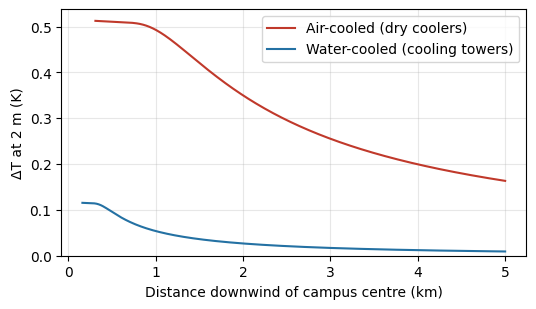

In [3]:
x = np.linspace(50, 5000, 400)            # m downwind of the campus centre
ra, rw = dp.plume(air, night, x), dp.plume(water, night, x)
print("air-cooled ΔT at 1 / 5 km:  ", np.round(np.interp([1000, 5000], x, ra["dT"]), 3), "K")
print("water-cooled ΔT at 1 / 5 km:", np.round(np.interp([1000, 5000], x, rw["dT"]), 3), "K")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(x / 1000, ra["dT"], color="#c0392b", label="Air-cooled (dry coolers)")
ax.plot(x / 1000, rw["dT"], color="#2471a3", label="Water-cooled (cooling towers)")
ax.set(xlabel="Distance downwind of campus centre (km)", ylabel="ΔT at 2 m (K)", ylim=(0, None))
ax.legend(); ax.grid(alpha=.3)

## A 2-D map

Pass `x` and `y` arrays that broadcast together (`x[:, None]`, `y[None, :]`). Points inside the footprint return NaN.

[Text(0.5, 0, 'Along wind (km)'), Text(0, 0.5, 'Across wind (km)'), None]

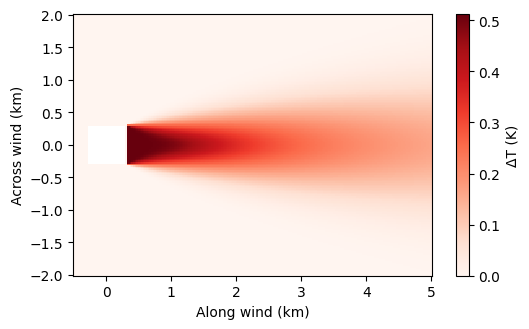

In [4]:
X = np.linspace(-500, 5000, 221)[:, None]
Y = np.linspace(-2000, 2000, 161)[None, :]
m = dp.plume(air, night, X, Y)["dT"]
fig, ax = plt.subplots(figsize=(6, 3.4))
pc = ax.pcolormesh(X.ravel() / 1000, Y.ravel() / 1000, m.T, cmap="Reds", shading="auto")
fig.colorbar(pc, label="ΔT (K)")
ax.set(xlabel="Along wind (km)", ylabel="Across wind (km)", aspect="equal")

## Night versus day, and why the fan array matters

By day, a single merged plume from a 600 m array would rise hundreds of metres and leave the ground layer, so it predicts almost no warming. Measured traverses near Phoenix data centers show 0.5–1 °C (tutorial 2). With `fan_heat` set, each fan plume rises only tens of metres and convective mixing brings the heat down.

In [5]:
day = dp.Ambient(T=40.0, RH=0.12, U10=1.5, stability="C", mixing_height=1500.0, elevation=340.0)
air_day = dp.dry_cooler_source(137e6, 12.0, day, height=12.0, footprint_x=600.0, footprint_y=600.0,
                               building_height=10.0, exit_velocity=3.0, fan_heat=80e3)
merged = dp.dry_cooler_source(137e6, 12.0, day, height=12.0, footprint_x=600.0, footprint_y=600.0,
                              building_height=10.0, exit_velocity=3.0, fan_heat=None)
for name, src in [("fan array (80 kW per fan)", air_day), ("one merged plume", merged)]:
    r = dp.plume(src, day, np.array([1000.0]))
    print(f"{name:28s} rise {r['final_rise']:7.1f} m   ΔT at 1 km {r['dT'][0]:.3f} K")

fan array (80 kW per fan)    rise    11.5 m   ΔT at 1 km 0.999 K
one merged plume             rise  1831.8 m   ΔT at 1 km 0.001 K


## Long-term exposure: the wind-direction average

`mode="radial"` averages over uniformly distributed wind directions. Use it for long-term exposure at a fixed location; the plume axis describes one hour with steady wind.

In [6]:
rad = dp.plume(air, night, x, mode="radial")
print("axis vs wind-direction average at 1 km:",
      round(float(np.interp(1000, x, ra["dT"])), 3), "/", round(float(np.interp(1000, x, rad["dT"])), 3), "K")

axis vs wind-direction average at 1 km: 0.493 / 0.048 K


## Next steps

- `02_validation_sailor2026.ipynb` reproduces the comparison with published field measurements.
- `analysis/exceedance.py` counts the hours per year above 1 K around a campus (`python building_energy/get_weather.py` first).
- `docs/technical_reference.md` lists every equation and assumption.